### SMSA 19.3 — The pentagon with associators that are not identities

**Source.** SMSA 7.8, 2026-11-05 (local `smsa.pdf`, SHA-256 `6922b174…813b8fe`). References are section and equation numbers of that version. **Translation conventions.** `f >> g` is SMSA's $g\circ f$ (first $f$, then $g$); `f @ g` is $f\otimes g$ with the left factor on the left. Native DisCoPy drawings read **top to bottom**, SMSA reads bottom to top; left-to-right order is unchanged. Only built-in DisCoPy 1.2.2 objects and methods are used: no custom functions, classes or rewrite rules. Checks print the computed and expected values with a comparison result and continue when a comparison is `False`.

In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


Definition 19.3.5 asks that the two routes round the pentagon (19.22) agree. In standard product bases, the canonical associator of these finite-dimensional vector spaces has the identity matrix. DisCoPy's tensor of types omits brackets, so the following comparison checks equality of types:

In [1]:
from discopy import monoidal
U, V, W = map(monoidal.Ty, 'UVW')
print('(U @ V) @ W == U @ (V @ W):', (U @ V) @ W == U @ (V @ W))

(U @ V) @ W == U @ (V @ W): True


The pentagon has content in a fusion category (§19.4), where the associators act on spaces of coupling trees by $F$-matrices.

**Fusion rules and $F$-symbols used here.** Labels $1$ (vacuum), $2$ ($\sigma$), $3$ ($\psi$) with the Ising fusion rules $2\times2=1+3$, $2\times3=2$, $3\times3=1$, and $1$ the unit. The $F$-symbol $(F^{abc}_d)_{ef}$ relates the coupling tree $((a\,b)_e\,c)_d$ to the tree $(a\,(b\,c)_f)_d$: $|((ab)_e c)_d\rangle=\sum_f (F^{abc}_d)_{ef}\,|(a(bc)_f)_d\rangle$. The numbers are the solution of the full pentagon system in the course notebook `from_fusion_to_solving_pentagon.nb`: unit gauge (an $F$ with a vacuum among $a,b,c$ equals $1$ when admissible), $F^{222}_2$ the Hadamard matrix with positive upper-left entry, and $(F^{232}_3)_{22}=(F^{323}_2)_{22}=-1$. SMSA's (19.25) defines $F^{(ijk)l}_{p,q}$ in the opposite direction, right tree in terms of left trees, which is the inverse matrix; every Ising $F$-matrix is real, symmetric and its own inverse, so the two conventions give the same numbers with $p$ read as the right channel and $q$ as the left channel.

Take four objects of type $2$ with total type $3$. Each of the five bracketings has a two-dimensional space of coupling trees, with a basis labelled by the one free intermediate channel:

| vertex of (19.22) | bracketing | basis |
|---|---|---|
| $A$ | $(((2\,2)_p\,2)_2\,2)_3$ | $p\in\{1,3\}$ |
| $B$ | $((2\,(2\,2)_x)_2\,2)_3$ | $x\in\{1,3\}$ |
| $C$ | $(2\,((2\,2)_x\,2)_2)_3$ | $x\in\{1,3\}$ |
| $D$ | $(2\,(2\,(2\,2)_s)_2)_3$ | $s\in\{1,3\}$ |
| $E$ | $((2\,2)_p\,(2\,2)_s)_3$ | $(p,s)\in\{(1,3),(3,1)\}$ |

Each arrow of the pentagon is a $2\times2$ matrix of $F$-symbols, supplied below as the array of a native `tensor.Box` on the two-dimensional type `Dim(2)`. Rows index the input basis, columns the output basis.

In [2]:
from discopy import tensor
from discopy.drawing import Equation
import numpy as np
D2 = tensor.Dim(2)
Had = np.array([[1, 1], [1, -1]]) / np.sqrt(2)      # F^{222}_2, channels ordered (1, 3)
Zm = np.diag([1, -1])                              # (F^{2x2}_3)_{22} for x = 1, 3
Xm = np.array([[0, 1], [1, 0]])                    # (F^{22s}_3)_{p2} with (p, s) = (1, 3), (3, 1)
a_AB = tensor.Box('a(2,2,2) ⊗ id', D2, D2, Had)
a_BC = tensor.Box('a(2,(2 2),2)', D2, D2, Zm)
a_CD = tensor.Box('id ⊗ a(2,2,2)', D2, D2, Had)
a_AE = tensor.Box('a((2 2),2,2)', D2, D2, np.eye(2, dtype=int))
a_ED = tensor.Box('a(2,2,(2 2))', D2, D2, Xm)
long_route = a_AB >> a_BC >> a_CD
short_route = a_AE >> a_ED
print('long route  (A -> B -> C -> D):', long_route)
print('short route (A -> E -> D):', short_route)
print('Equal as free diagrams:', long_route == short_route)
print('Long route evaluated (rounded to 12 digits):')
print(np.round(long_route.eval().array, 12))
print('Short route evaluated:')
print(short_route.eval().array)
print('Pentagon (19.22) holds for these F-symbols (NumPy allclose):', np.allclose(long_route.eval().array, short_route.eval().array))
print('The same block as matrices, H Z H == X:', np.allclose(Had @ Zm @ Had, Xm))

long route  (A -> B -> C -> D): a(2,2,2) ⊗ id >> a(2,(2 2),2) >> id ⊗ a(2,2,2)
short route (A -> E -> D): a((2 2),2,2) >> a(2,2,(2 2))
Equal as free diagrams: False
Long route evaluated (rounded to 12 digits):
[[-0.  1.]
 [ 1. -0.]]
Short route evaluated:
[[0 1]
 [1 0]]
Pentagon (19.22) holds for these F-symbols (NumPy allclose): True
The same block as matrices, H Z H == X: True


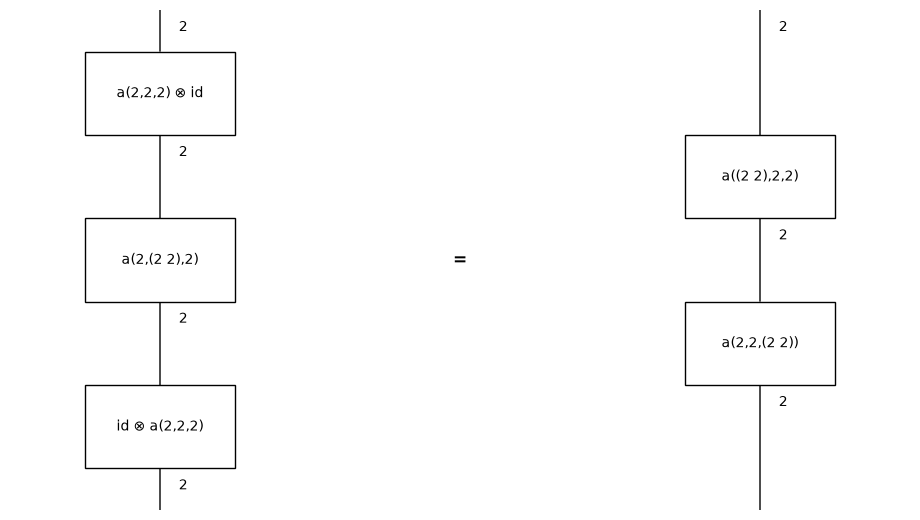

In [3]:
Equation(long_route, short_route, symbol='=').draw(figsize=(9, 5))

**What was established.** The five boxes are typed on the two-dimensional tree spaces, so composition checks the endpoints (built in). The two routes are different free diagrams, and the pentagon holds because their evaluated matrices agree: $HZH=X$, verified for these supplied $F$-symbols. This is one block of the pentagon system (19.30), the one for four objects of type $2$ with total type $3$; the notebook for §19.4 checks every block. Whether a given set of $F$-symbols satisfies the pentagon is decided by evaluation; nothing in the free syntax supplies it.

### The triangle (19.23)

The second axiom of Definition 19.3.5 relates the associator with a unit in the middle to the two unitors: $(\mathrm{id}_V\otimes l_W)\circ a_{V,1,W}=r_V\otimes\mathrm{id}_W$. For vector spaces the library absorbs the unit, exactly as for the pentagon:

In [4]:
print('V @ Ty() @ W == V @ W:', V @ monoidal.Ty() @ W == V @ W)


V @ Ty() @ W == V @ W: True


In the Ising data of §19.4 take $V=W=2$ with total type $d$. The vacuum fuses uniquely, $2\times1=2$, so the tree space of $((2\,1)_2\,2)_d$ and that of $(2\,(1\,2)_2)_d$ are both one-dimensional, and every arrow of the triangle is a $1\times1$ matrix, a number. The three tree spaces are named by their brackets, as in (19.23), and a `tensor.Functor` sends each to a one-dimensional space. In the forward/course convention introduced above, the associator is the $F$-symbol $(F^{212}_d)_{22}$ and the unitors are the numbers by which the one-dimensional vertex spaces $(2\,1)_2$ and $(1\,2)_2$ are identified with $V$ and $W$. The triangle then reads $l\cdot a=r$. In the unit gauge of `from_fusion_to_solving_pentagon.nb` all three numbers are $1$ and the triangle is $1=1$. Remark 19.4.5 says that the values depend on the chosen basis of each tree space, including the one-dimensional ones: rescaling the two vertex bases by $e^{i\theta}$ and $e^{i\varphi}$ changes the unitors to those numbers and forces the vacuum $F$-symbol to $e^{i(\theta-\varphi)}$. The control changes the $F$-symbol alone and breaks the triangle. The triangle therefore has content: it ties the vacuum $F$-symbols to the unitor gauge.

To keep the direction explicit, let $L=e^{i\theta}L_0$ and $R=e^{i\varphi}R_0$ be the two tree bases, with the common reduced basis fixed. Then $L=(r/l)R$ and $R=(l/r)L$. Thus the forward associator coefficient is $a=r/l$, while the coefficient in SMSA's opposite expansion (19.25) is $a^{-1}$. These complex coefficients need not coincide, unlike the supplied unit-gauge Ising matrices.


unit gauge: route a then id⊗l = (1+0j) ; route r⊗id = (1+0j) ; triangle holds: True
vertex bases rescaled: route a then id⊗l = (0.764842187284+0.644217687238j) ; route r⊗id = (0.764842187284+0.644217687238j) ; triangle holds: True
control: F-symbol changed alone: route a then id⊗l = (-0.856888753369+0.515501371821j) ; route r⊗id = (1+0j) ; triangle holds: False
Forward coefficient L in R: (-0.8568887533689472+0.5155013718214645j) ; SMSA opposite coefficient R in L: (-0.8568887533689471-0.5155013718214643j)
L = forward * R: (0.7648421872844885+0.644217687237691j) (0.7648421872844886+0.644217687237691j) True
R = SMSA * L: (-0.32328956686350335-0.9463000876874145j) (-0.32328956686350335-0.9463000876874145j) True
Inverse coefficients: (1-1.398292643274959e-16j) ; expected 1: True


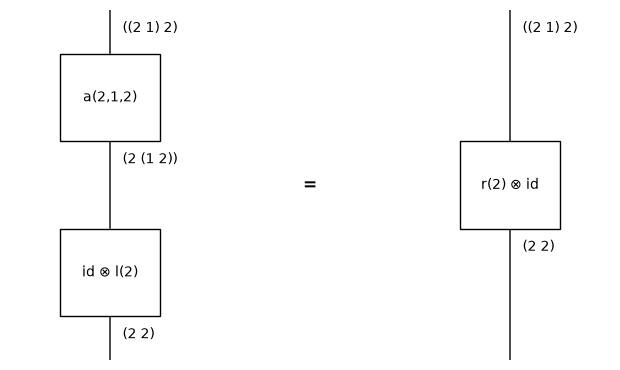

In [5]:
from discopy import symmetric
T_left, T_mid, T_right = map(symmetric.Ty, ['((2 1) 2)', '(2 (1 2))', '(2 2)'])
a_V1W = symmetric.Box('a(2,1,2)', T_left, T_mid)
l_W = symmetric.Box('id ⊗ l(2)', T_mid, T_right)
r_V = symmetric.Box('r(2) ⊗ id', T_left, T_right)
theta, phi = 0.7, -1.9
for gauge, (a_val, r_val, l_val) in [('unit gauge', (1, 1, 1)),
                                      ('vertex bases rescaled', (np.exp(1j * (theta - phi)), np.exp(1j * theta), np.exp(1j * phi))),
                                      ('control: F-symbol changed alone', (np.exp(1j * (theta - phi)), 1, 1))]:
    F_tri = tensor.Functor({T_left: 1, T_mid: 1, T_right: 1}, {a_V1W: [[a_val]], l_W: [[l_val]], r_V: [[r_val]]}, dom=symmetric.Category(), dtype=complex)
    upper = F_tri(a_V1W >> l_W).array
    lower = F_tri(r_V).array
    print(gauge + ': route a then id⊗l =', np.round(upper, 12), '; route r⊗id =', np.round(lower, 12), '; triangle holds:', np.allclose(upper, lower))
Equation(a_V1W >> l_W, r_V, symbol='=').draw(figsize=(6, 3.5))

left_basis, right_basis = np.exp(1j * theta), np.exp(1j * phi)
forward_coefficient = left_basis / right_basis
smsa_coefficient = right_basis / left_basis
print("Forward coefficient L in R:", forward_coefficient, "; SMSA opposite coefficient R in L:", smsa_coefficient)
print("L = forward * R:", left_basis, forward_coefficient * right_basis, np.allclose(left_basis, forward_coefficient * right_basis))
print("R = SMSA * L:", right_basis, smsa_coefficient * left_basis, np.allclose(right_basis, smsa_coefficient * left_basis))
print("Inverse coefficients:", forward_coefficient * smsa_coefficient, "; expected 1:", np.allclose(forward_coefficient * smsa_coefficient, 1))


**What was established.** The triangle holds in the unit gauge and in the rescaled gauge, and fails when the $F$-symbol is changed without the unitors, for the one labelled component $V=W=2$; other labels with a vacuum in the middle behave the same way because their tree spaces are also one-dimensional. The drawn picture is the unit-gauge instance, with three named boxes on the one-dimensional tree spaces; it is the triangle of (19.23) with the bracketed objects replaced by those spaces.